In [1]:
# Colab only: clone the repo and move into the project root
import os
import sys

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    # Clone repository if it hasn't been cloned yet
    if not os.path.exists('/content/convolutional_vae_quishing'):
        !git clone https://github.com/AnhJoe/convolutional_vae_quishing.git

    # Change working directory to the project root
    os.chdir('/content/convolutional_vae_quishing')

In [2]:
#| output: false
# Local only: find the project root (the folder containing src/) and add it to the import path
# For local runs. Else if running Colab, skip this.

import sys
from pathlib import Path

# Set to root for src load
root = Path.cwd()
while root != root.parent and not (root / "src").exists():
    root = root.parent

if not (root / "src").exists():
    raise FileNotFoundError("Could not find 'src' folder above current working directory.")

sys.path.insert(0, str(root))
print("Project root:", root)

Project root: c:\Users\joetn\convolutional_vae_quishing


# Image VAE

This notebook is the starting point for everything that works on the QR images: the image floors, the convolutional VAE and the image supervised reference. The data, the splits and the evaluation functions are already imported, so the first cells below only need to be run, and the model sections are where the work goes.

What is ready:

- **The items table** (`items`), with one row per QR code that fits the 65 x 65 canvas: label, split, QR size, dark-pixel fraction and the rest. It was built by `2_data_processing.ipynb`, which must be run first.
- **The checks.** `src/checks.py` tests the items table, the model input and the evaluation functions, and the notebook runs them at the points where they matter.
- **The model input.** `load_qr_grids` turns rows of the table into 65 x 65 arrays of modules (1 is a dark module, 0 is a light one), the same way for everyone.
- **The evaluation functions.** A model saves one anomaly score per item, and `save_and_evaluate` turns the saved scores into the project metrics (AUROC, AUPRC, recall at 1% and 5% false-positive rate). The score format is described at the top of `src/evaluate.py`.

The URL models live in `4_url_vae.ipynb`. Image models are scored only on codes that fit the canvas, so their numbers are not directly comparable with the URL models (different test items).

## 1. Data

The full items table (`all_items`) holds every kept code. The image models use only the codes that fit the 65 x 65 canvas (`items`), because a larger code cannot be put on the canvas without cropping. The checks run on the full table first, so a problem in the data shows up before any filtering.

In [3]:
# Imports and settings. Add the deep learning library (torch) here when building the model, and add it to requirements.txt
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import checks
from src.evaluate import save_and_evaluate
from src.loaders import CANVAS, cached_grids, load_qr_grids
from src.prepare_data import load_items
from src.splits import SPLIT_NAMES

PROC_DIR = root / "data" / "processed"
RAW_DIR = root / "data" / "raw"
RESULTS_DIR = root / "results"
SCOPE = "canvas"    # image models are scored only on codes that fit the canvas (see src/evaluate.py)
SEED = 0

In [4]:
# Load the full items table and its summary, then keep the codes that fit the canvas and split them into the sets each model uses
all_items = load_items(PROC_DIR)
summary = json.loads((PROC_DIR / "items_summary.json").read_text())
items = all_items[all_items["fits_canvas"]].reset_index(drop=True)

benign_train = items[(items["split"] == "train") & (items["cls"] == "benign")]
malicious_train = items[(items["split"] == "train") & (items["cls"] == "malicious")]
validation = items[items["split"] == "validation"]
test = items[items["split"] == "test"]

pd.DataFrame({
    "benign": items[items["cls"] == "benign"].groupby("split").size(),
    "malicious": items[items["cls"] == "malicious"].groupby("split").size(),
}).loc[SPLIT_NAMES]

,benign,malicious
split,,
train,300863,398749
validation,64471,86248
test,64466,86240


**Who uses which rows**

| Model | Fitted on | Tuned on | Threshold set on | Scored on |
| --- | --- | --- | --- | --- |
| Floors and the VAE | benign train rows | validation rows | benign validation rows | validation and test rows |
| Supervised reference | benign and malicious train rows | validation rows | benign validation rows | validation and test rows |

The test rows are used once per model, after the configuration is fixed on validation. Malicious train rows are used only by the supervised reference.

In the code above, `benign_train` is what the floors and the VAE are fitted on, `malicious_train` is used only by the supervised reference, and `validation` and `test` are scored.

## Checks on the data

Before any model is built, the next cell runs a set of checks on the items table and prints one row per check. Each row is `pass` or `FAIL`, and the cell stops with an error if any check fails, so a broken table cannot reach a model by accident. The checks confirm that the table matches `items_summary.json` (the row counts and the data version, which everyone on the team should see as the same value), that every split has both classes, that no registered domain sits in two splits of the same class, and that the URL columns are consistent. For the image models it also checks that the image measurements (`modules`, `dark_frac` and the rest) are filled for every code on the canvas, that they agree with the PNG width, and how many codes were left out for being too large. Rows marked `info` are measurements for the reader and cannot fail.

In [5]:
# Run the data checks on the full items table (stops with an error if any check fails)
checks.data_checks(all_items, summary, SCOPE).report()

check,result,detail
row count matches items_summary.json,pass,"1,005,700 rows"
data version matches items_summary.json,pass,0781657d11c5. Everyone on the team should see the same value
item_id equals the row position,pass,
label matches the class folder,pass,
rows per split and class match items_summary.json,pass,"train: 300,969 benign, 403,020 malicious; validation: 64,494 benign, 86,361 malicious; test: 64,494 benign, 86,362 malicious"
every split has benign and malicious rows,pass,
no domain appears in two splits of the same class,pass,
malicious share of every split is within 1 point of the overall share,pass,"train 0.572, validation 0.572, test 0.572 (overall 0.572)"
"no empty URL, and url_len equals the URL length",pass,
truncated is true exactly for URLs longer than 256,pass,"5,742 truncated"


## 2. Look at the model input

A QR code is stored as a grid with one value per module. The quiet zone (the light margin around the code) is included, a smaller code sits in the top-left corner of the 65 x 65 canvas, and the rest of the canvas is light.

array shape: (16, 65, 65) | values: [0 1]


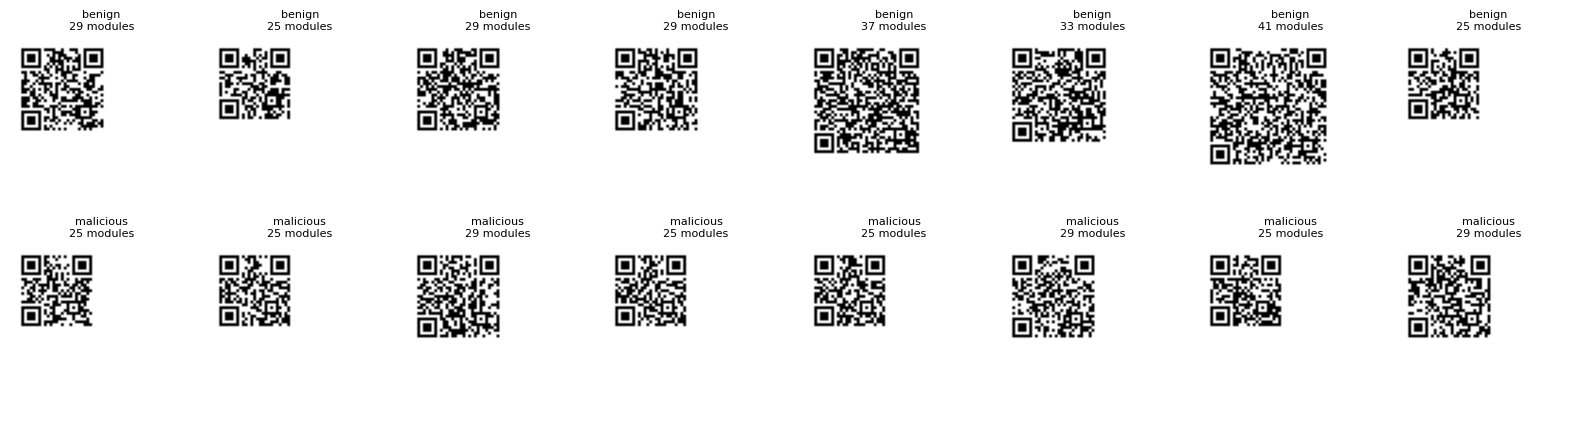

In [6]:
# Show 8 benign and 8 malicious training codes as the model sees them (black is a dark module)
show = pd.concat([benign_train.sample(8, random_state=SEED), malicious_train.sample(8, random_state=SEED)])
grids = load_qr_grids(RAW_DIR, show)
print("array shape:", grids.shape, "| values:", np.unique(grids))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, g, (_, r) in zip(axes.ravel(), grids, show.iterrows()):
    ax.imshow(1 - g, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{r['cls']}\n{r['modules']:.0f} modules", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

Reading every PNG is slow (hundreds of thousands of files for the training set). `cached_grids(RAW_DIR, rows, path)` reads the images once, saves the arrays to `path`, and loads them from there on later calls. Use it for the large sets, for example `cached_grids(RAW_DIR, benign_train, PROC_DIR / "grids_benign_train.npz")`. Files under `data/processed/` are git-ignored.

## Checks on the model input

The next cell reads about 200 training codes (100 per class, plus the smallest and the largest grids) and checks the arrays the model will receive: shape and type, only 0 and 1 as values, nothing drawn outside the code's own grid, a light quiet zone, a dark share that matches `dark_frac`, that `cached_grids` returns the same arrays as `load_qr_grids`, and that a code larger than the canvas is refused instead of cropped. It also reports the reading speed, which says how long a first pass over the training set takes without the cache.

In [7]:
# Run the model input checks on a small sample of real images
checks.image_input_checks(RAW_DIR, all_items).report()

check,result,detail
"array shape is (n, 65, 65) and the type is uint8",pass,"(206, 65, 65), uint8"
values are only 0 (light module) and 1 (dark module),pass,
nothing is drawn outside the code's own grid (top-left anchoring),pass,including the smallest and largest grids
"the quiet zone is light on all four sides and the first dark module sits at (border, border)",pass,
the dark share of each array equals dark_frac of the items table,pass,largest difference 5.6e-17
"cached_grids returns the same arrays as load_qr_grids, and rebuilds when the items change",pass,
a code larger than the canvas is refused instead of cropped,pass,grid 89
reading speed,info,"0.8 ms per image in this run, so about 4 minutes for the 300,863 benign train codes. Use cached_grids so the images are read once"


## 3. Floors

A floor is a deliberately simple detector that uses no image pattern, only trivial properties of the code. A VAE is only useful if it beats its floor. Both image floors use the same two features, the number of modules per side and the dark-pixel fraction (`1_eda.ipynb` section 7). Each is a Gaussian fitted on `benign_train` only, and the score is the Mahalanobis distance from it (a distance that accounts for how the two features vary together, so unusual combinations score high). Floor A is the headline floor and floor B is reported alongside it. For images they are identical, so one set of scores serves both.

In [8]:
# Floor features (columns of the items table). Fit on benign train rows only, then score validation and test rows
FLOOR_FEATURES = ["modules", "dark_frac"]
# 1. Fit: mean and covariance of benign_train[FLOOR_FEATURES], with a small ridge added to the covariance.
# 2. Score: Mahalanobis distance of every validation and test row from that Gaussian.
# 3. Save and evaluate, one call per floor:
#    save_and_evaluate(RESULTS_DIR, items, SCOPE, "floorA_image", "mahalanobis", 0,
#                      validation=(validation["item_id"], val_scores), test=(test["item_id"], test_scores))

## 4. Convolutional VAE

Train on `benign_train` only, tune on `validation` only (latent size, beta, input resolution and the likelihood for 1-bit images), then train at least 5 seeds of the chosen setup. Log the ELBO, the reconstruction term and the KL term against training iteration. The scores to save (higher means more likely malicious, one value per item) are:

- `recon_error`: reconstruction error
- `neg_elbo`: the negative ELBO
- `kl`: the KL term
- `mahalanobis`: distance of the encoder mean from a Gaussian fitted to the benign training encodings

Save each with `save_and_evaluate(RESULTS_DIR, items, SCOPE, "image_vae", "<score name>", seed, ...)`.

In [9]:
# Build, train and score the convolutional VAE here

## 5. Supervised reference

The reference is the VAE's encoder plus one linear layer, trained from scratch with labels on `benign_train` and `malicious_train` using binary cross-entropy. Reusing the encoder architecture matches the capacity, so a gap to the VAE does not come from network size. It is context only, not a contribution, because the project itself must be generative. Save its scores as model `image_supervised`, score `prob_malicious` (the predicted probability of malicious).

**Read the reference results with two caveats.**

1. **The training data differs.** The VAE and the floors train on benign train rows only. The reference trains on benign and malicious train rows (more than twice as many). The gap between the VAE and its reference therefore measures what labels and malicious examples add, and part of it can come from simply having more data. Word it that way, not as "supervision alone". One optional check is to also train a reference on a random subset the size of the benign train set.
2. **The reference can use shortcuts directly.** A labeled model can learn that QR size and dark-pixel fraction point to a class (`1_eda.ipynb` sections 4 and 5 show both differ between classes). A high reference score may therefore mostly reflect those properties. Read the reference results next to floor A and within the QR-version strata, and do not describe them as an upper bound on what the QR content carries.

A third point applies to the VAE and the reference equally: tuning on validation AUROC uses validation labels for model selection.

In [10]:
# Build, train and score the supervised reference here

## 6. Evaluate

Every model, floor and supervised reference is evaluated with the same call, `save_and_evaluate`, once per score and per seed. The model never computes a metric itself. The call:

1. saves the validation and test scores to `results/<model>/<score>/seed<k>/validation.csv.gz` and `test.csv.gz`,
2. checks them against the items table (exactly the items of the split, one finite score each, higher meaning more likely malicious),
3. returns one row of metrics: AUROC, AUPRC, recall at 1% and 5% false-positive rate, and the share of benign test items actually flagged at those thresholds. The alarm threshold is set on the benign validation rows only.

This section first shows that the pipeline works, then shows how to use it.

### Check that the evaluation pipeline works

The next cell runs `checks.evaluation_checks` with made-up scores in a temporary folder, so nothing is written to `results/`. Random scores must give an AUROC near 0.5, an AUPRC near the malicious share and about 1% and 5% of benign test items flagged. Perfect scores must give 1 everywhere, reversed scores must give an AUROC of 0, and a score file with a missing item, an unknown item or a NaN must be refused. Once real models exist, this cell can stay as a regression check.

In [11]:
# Run the evaluation checks with made-up scores in a temporary folder
checks.evaluation_checks(items, SCOPE).report()

check,result,detail
random scores give AUROC near 0.5,pass,AUROC 0.5002
random scores give AUPRC near the malicious share,pass,"AUPRC 0.5724, malicious share 0.5722"
random scores flag about 1% and 5% of test benign items at the validation thresholds,pass,0.99% and 5.10%
"perfect scores give AUROC 1, AUPRC 1 and recall 1 with no false alarms",pass,"AUROC 1.000, AUPRC 1.000, recall at 1% FPR 1.000"
reversed scores give AUROC 0 (higher must mean more malicious),pass,AUROC 0.000
a validation file that misses one item is refused,pass,
a validation file with an item that is not in the split is refused,pass,
scores with a missing value (NaN) are refused,pass,


### How to evaluate a model

The arguments are the results folder, the items table, `SCOPE`, the model name (`image_vae`), the score name (`neg_elbo`), the seed, and a pair of (item ids, scores) for validation and for test. The example below runs the call for two seeds with random numbers standing in for a model, then stacks the rows into one table.

It saves to `results/temp_demo_results/`, a folder that only holds this demo, so it can be deleted at any time and rerunning the cell overwrites it. In a real run, replace the random numbers with the model's scores and use `RESULTS_DIR` instead of `DEMO_DIR`, so the files land in `results/<model>/<score>/seed<k>/`.

In [12]:
# Example of the evaluate step: stand-in scores for two seeds, saved under results/temp_demo_results/ (use RESULTS_DIR in a real run)
DEMO_DIR = RESULTS_DIR / "temp_demo_results"
rng = np.random.default_rng(SEED)
rows = []
for seed in range(2):                                       # one call per seed
    val_scores = rng.normal(size=len(validation))           # one score per validation item, higher means more likely malicious
    test_scores = rng.normal(size=len(test))                # one score per test item
    metrics = save_and_evaluate(DEMO_DIR, items, SCOPE, "image_vae", "neg_elbo", seed,
                                validation=(validation["item_id"], val_scores),
                                test=(test["item_id"], test_scores))
    rows.append(metrics)                                    # one row per run, with the model, score and seed in it
pd.concat(rows, ignore_index=True)

,model,score,seed,scope,n_benign,n_malicious,prevalence,auroc,auprc,validation_auroc,recall_at_1pct_fpr,test_fpr_at_1pct,recall_at_5pct_fpr,test_fpr_at_5pct
0,image_vae,neg_elbo,0,canvas,64466,86240,0.57224,0.500228,0.572352,0.498845,0.009775,0.009912,0.050974,0.051019
1,image_vae,neg_elbo,1,canvas,64466,86240,0.57224,0.499689,0.571735,0.500051,0.010181,0.011169,0.050800,0.051004
